In [1]:
import os
for f in sorted(os.listdir(".")):
    if os.path.isfile(f):
        print(f, round(os.path.getsize(f) / 1e6, 1), "MB")

.bash_logout 0.0 MB
.bash_profile 0.0 MB
.bashrc 0.0 MB
Churn_Scikit_PyTorch.ipynb 0.6 MB
Digit_Class_TensorFlow.ipynb 0.0 MB
Fraud_LSTM_Keras_TF.ipynb 0.2 MB
HI-Small_Trans.csv.gz 87.8 MB
Loan_Approval_Demo.ipynb 0.0 MB
Untitled.ipynb 0.0 MB
Untitled1.ipynb 0.0 MB
Untitled2.ipynb 0.0 MB
Untitled3.ipynb 0.0 MB
Varshini_work.ipynb 0.0 MB
clients.csv 0.3 MB
customer_churn_decision_tree_model.pmml 0.5 MB
fraud_lstm.onnx 2.5 MB
granite-4.0-h-350m-base-be.f16.gguf 684.9 MB
krash.ipynb 0.0 MB
model.png 0.1 MB
test_220_40k.csv 17.7 MB
test_220_40k.indices 0.3 MB
transactions.csv 3.2 MB
transactions_history.csv 23.2 MB
varshini_lab01.ipynb 0.0 MB


In [2]:
import pandas as pd
import glob

files = glob.glob("*.csv.gz")
print(files)

df = pd.read_csv(files[0])
print(files[0])
print(df.shape)
df.head()

['HI-Small_Trans.csv.gz']
HI-Small_Trans.csv.gz
(5078345, 11)


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


In [3]:
if df.shape[1] == 11:
    df.columns = ["timestamp", "from_bank", "from_acct", "to_bank", "to_acct",
                  "amt_received", "recv_currency", "amt_paid", "pay_currency",
                  "pay_format", "is_laundering"]
    print(df["is_laundering"].value_counts())
    print("laundering rate:", round(df["is_laundering"].mean() * 100, 3), "%")
    print("number of banks:", df["from_bank"].nunique())
else:
    print("Unexpected number of columns:", df.shape[1])
    print(list(df.columns))

is_laundering
0    5073168
1       5177
Name: count, dtype: int64
laundering rate: 0.102 %
number of banks: 30470


In [4]:
df["src"] = df["from_bank"].astype(str) + "_" + df["from_acct"].astype(str)
df["dst"] = df["to_bank"].astype(str) + "_" + df["to_acct"].astype(str)

out = df.groupby("src").agg(out_count=("dst", "size"),
                            fan_out=("dst", "nunique"),
                            out_amt=("amt_paid", "sum"))
inc = df.groupby("dst").agg(in_count=("src", "size"),
                            fan_in=("src", "nunique"),
                            in_amt=("amt_paid", "sum"))

feat = out.join(inc, how="outer").fillna(0)

bad = pd.concat([df.loc[df["is_laundering"] == 1, "src"],
                 df.loc[df["is_laundering"] == 1, "dst"]]).unique()
feat["label"] = feat.index.isin(bad).astype(int)
feat["bank"] = feat.index.str.split("_").str[0]

print(feat.shape)
print(feat["label"].value_counts())
feat.head()

(515088, 8)
label
0    508731
1      6357
Name: count, dtype: int64


,out_count,fan_out,out_amt,in_count,fan_in,in_amt,label,bank
src,,,,,,,,
10057_801FB1090,0.0,0.0,0.000000e+00,1.0,1.0,0.01,0,10057
10057_803A115E0,15.0,2.0,1.042617e+07,1.0,1.0,146954.27,0,10057
10057_803AA8E90,44.0,4.0,1.454908e+08,24.0,2.0,38170762.68,0,10057
10057_803AAB430,4.0,3.0,1.550276e+07,16.0,3.0,1266401.69,0,10057
10057_803AACE20,65.0,4.0,4.518459e+08,18.0,3.0,54687912.83,0,10057


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, precision_score, recall_score
import lightgbm as lgb

cols = ["out_count", "fan_out", "out_amt", "in_count", "fan_in", "in_amt"]
X = feat[cols]
y = feat["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

model = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1,
                           scale_pos_weight=80, verbose=-1)
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
pred = (proba > 0.5).astype(int)

print("AUC:", round(roc_auc_score(y_test, proba), 3))
print("precision:", round(precision_score(y_test, pred), 3))
print("recall:", round(recall_score(y_test, pred), 3))

AUC: 0.842
precision: 0.042
recall: 0.719


In [6]:
for t in [0.5, 0.7, 0.8, 0.9, 0.95]:
    pred_t = (proba > t).astype(int)
    print("cutoff", t,
          "| flagged:", int(pred_t.sum()),
          "| precision:", round(precision_score(y_test, pred_t, zero_division=0), 3),
          "| recall:", round(recall_score(y_test, pred_t), 3))

cutoff 0.5 | flagged: 32471 | precision: 0.042 | recall: 0.719
cutoff 0.7 | flagged: 16718 | precision: 0.059 | recall: 0.514
cutoff 0.8 | flagged: 7964 | precision: 0.078 | recall: 0.325
cutoff 0.9 | flagged: 892 | precision: 0.145 | recall: 0.068
cutoff 0.95 | flagged: 66 | precision: 0.424 | recall: 0.015


In [8]:
import hmac, hashlib, secrets

CUTOFF = 0.8
SECRET_KEY = secrets.token_bytes(32)

def make_token(account_id):
    return hmac.new(SECRET_KEY, account_id.encode(), hashlib.sha256).hexdigest()[:16]

scored = pd.DataFrame({"account": X_test.index,
                       "risk": proba,
                       "label": y_test.values})

alerts = scored[scored["risk"] > CUTOFF].copy()
alerts["token"] = alerts["account"].map(make_token)
alerts["risk_flag"] = 1

shared = alerts[["token", "risk_flag"]]

print("accounts flagged:", len(alerts))
print("truly laundering among flagged:", int(alerts["label"].sum()))
print("columns that would be shared:", list(shared.columns))
shared.head()

accounts flagged: 7964
truly laundering among flagged: 619
columns that would be shared: ['token', 'risk_flag']


,token,risk_flag
37,af38df92d7a22182,1
48,ac2e5db0f3c437d6,1
49,c4a1fd9ab223dee9,1
52,d2071f1b152b24d9,1
67,ed5c72031aef2098,1


In [9]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

flagged = set(alerts["account"])
mask = df["src"].isin(flagged) & df["dst"].isin(flagged)
edges = df.loc[mask, ["src", "dst"]].drop_duplicates().copy()
print("payments between flagged accounts:", len(edges))

if len(edges) == 0:
    print("No links found. Tell me and we will lower the cutoff.")
else:
    edges["t_src"] = edges["src"].map(make_token)
    edges["t_dst"] = edges["dst"].map(make_token)

    tokens = pd.unique(pd.concat([edges["t_src"], edges["t_dst"]]))
    idx = {t: i for i, t in enumerate(tokens)}
    r = edges["t_src"].map(idx).values
    c = edges["t_dst"].map(idx).values
    g = coo_matrix(([1] * len(r), (r, c)), shape=(len(tokens), len(tokens)))
    n, labels = connected_components(g, directed=False)

    bank_of = dict(zip(alerts["token"], alerts["account"].str.split("_").str[0]))
    label_of = dict(zip(alerts["token"], alerts["label"]))

    ring = pd.DataFrame({"token": tokens, "ring": labels})
    ring["bank"] = ring["token"].map(bank_of)
    ring["label"] = ring["token"].map(label_of)

    summary = ring.groupby("ring").agg(accounts=("token", "size"),
                                       banks=("bank", "nunique"),
                                       true_laundering=("label", "sum"))
    rings = summary[summary["accounts"] >= 3]
    multi = rings[rings["banks"] >= 2]

    print("rings with 3 or more accounts:", len(rings))
    print("rings that cross 2 or more banks:", len(multi))
    print(rings.sort_values("accounts", ascending=False).head(5))

payments between flagged accounts: 8501
rings with 3 or more accounts: 120
rings that cross 2 or more banks: 119
      accounts  banks  true_laundering
ring                                  
3641        46     32                6
3055        14      9                0
3942        12      9               10
3575        11      9                2
2613        10      7                0


In [10]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

tok2acct = dict(zip(alerts["token"], alerts["account"]))
ring["account"] = ring["token"].map(tok2acct)
ring_ids = set(multi.index)
members = ring[ring["ring"].isin(ring_ids)]
acct2ring = dict(zip(members["account"], members["ring"]))
acct = set(acct2ring)

link = df.loc[df["src"].isin(acct) & df["dst"].isin(acct),
              ["src", "dst", "timestamp"]].copy()
link["ring"] = link["src"].map(acct2ring)
link = link.sort_values("timestamp").drop_duplicates(["src", "dst"])
detect = link.groupby("ring")["timestamp"].apply(
    lambda s: s.iloc[1] if len(s) > 1 else s.iloc[0])

sub = df[df["src"].isin(acct) | df["dst"].isin(acct)].copy()
sub["ring"] = sub["src"].map(acct2ring).fillna(sub["dst"].map(acct2ring))
sub["detect"] = sub["ring"].map(detect)
after = sub[sub["timestamp"] > sub["detect"]]

total_bad = df.loc[df["is_laundering"] == 1, "amt_paid"].sum()
blocked_bad = after.loc[after["is_laundering"] == 1, "amt_paid"].sum()
blocked_good = after.loc[after["is_laundering"] == 0, "amt_paid"].sum()

print("rings used:", len(detect))
print("laundering payments blocked:", int((after["is_laundering"] == 1).sum()))
print("laundering money blocked:", round(blocked_bad))
print("share of all laundering money:", round(100 * blocked_bad / total_bad, 2), "%")
print("normal money wrongly blocked:", round(blocked_good))

rings used: 119
laundering payments blocked: 393
laundering money blocked: 2921528300
share of all laundering money: 1.56 %
normal money wrongly blocked: 25341397071


In [11]:
m = members.merge(alerts[["token", "risk"]], on="token")
ring_risk = m.groupby("ring")["risk"].mean()

def score(selected):
    a = after[after["ring"].isin(selected)]
    bad = a.loc[a["is_laundering"] == 1, "amt_paid"].sum()
    good = a.loc[a["is_laundering"] == 0, "amt_paid"].sum()
    return len(selected), round(100 * bad / total_bad, 2), round(bad), round(good)

for q in [0, 0.5, 0.75, 0.9]:
    sel = ring_risk[ring_risk >= ring_risk.quantile(q)].index
    n, pct, bad, good = score(sel)
    print("top", int((1 - q) * 100), "% of rings | rings:", n,
          "| laundering blocked %:", pct,
          "| laundering money:", bad,
          "| normal money wrongly blocked:", good)

top 100 % of rings | rings: 119 | laundering blocked %: 1.56 | laundering money: 2921528300 | normal money wrongly blocked: 25341397071
top 50 % of rings | rings: 60 | laundering blocked %: 1.55 | laundering money: 2907590758 | normal money wrongly blocked: 6500604930
top 25 % of rings | rings: 30 | laundering blocked %: 1.55 | laundering money: 2905528475 | normal money wrongly blocked: 2521830521
top 9 % of rings | rings: 12 | laundering blocked %: 0.02 | laundering money: 42165450 | normal money wrongly blocked: 419052463


In [12]:
import matplotlib.pyplot as plt
import numpy as np

nodes = list(ex["token"])
bank_of_tok = dict(zip(ex["token"], ex["bank"]))
n = len(nodes)
angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
pos = {t: (np.cos(a), np.sin(a)) for t, a in zip(nodes, angles)}

banks = sorted(set(bank_of_tok.values()))
cmap = plt.get_cmap("tab10")
color = {b: cmap(i % 10) for i, b in enumerate(banks)}

fig, ax = plt.subplots(figsize=(8, 8))
edges = flow[["from_token", "to_token"]].drop_duplicates()
for a, b in edges.itertuples(index=False):
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="gray", lw=1.2,
                                shrinkA=14, shrinkB=14))
for t in nodes:
    x, y = pos[t]
    ax.scatter(x, y, s=700, color=color[bank_of_tok[t]], zorder=3)
    ax.text(x * 1.2, y * 1.2, "Bank " + str(bank_of_tok[t]),
            ha="center", va="center", fontsize=9)
ax.set_title("RingFence: one ring linked across banks (tokens only)")
ax.axis("off")
plt.show()

NameError: name 'ex' is not defined

In [13]:
best = multi[multi["accounts"] <= 15].sort_values("true_laundering", ascending=False).index[0]

ex = members[members["ring"] == best].merge(alerts[["token", "risk"]], on="token")
acct2tok = dict(zip(ex["account"], ex["token"]))

print("RING", best, "| accounts:", len(ex), "| banks:", ex["bank"].nunique())
print()
print("What the banks share (token, bank, risk):")
print(ex[["token", "bank", "risk"]].sort_values("risk", ascending=False).round(3).to_string(index=False))

flow = df[df["src"].isin(acct2tok) & df["dst"].isin(acct2tok)].sort_values("timestamp").copy()
flow["from_token"] = flow["src"].map(acct2tok)
flow["to_token"] = flow["dst"].map(acct2tok)
print()
print("Payments inside the ring, in time order:")
print(flow[["timestamp", "from_token", "to_token", "amt_paid"]].head(12).to_string(index=False))

print()
print("Check with the answer key:", int(ex["label"].sum()), "of", len(ex), "accounts are truly laundering")

RING 3942 | accounts: 12 | banks: 9

What the banks share (token, bank, risk):
           token   bank  risk
4837c9a7c8a8b00d    118 0.978
63e4f531f5d9c1bf    119 0.938
bcffed97e866e8c5    222 0.932
826e0bdfee872910 148016 0.929
18046946f6c891e8  48211 0.915
ec26dbb5587df61a 149345 0.891
a721ceb6ee8962bd 148016 0.890
b84fd48e60db294e    121 0.887
7832d4b299b16335 249118 0.880
6d9c72a89d7fb3da    222 0.837
f9d411d276fb5ec0    118 0.830
9729c835dfc309d3    223 0.812

Payments inside the ring, in time order:
          timestamp       from_token         to_token   amt_paid
2022-09-01 00:02:00 18046946f6c891e8 18046946f6c891e8    1186.24
2022-09-01 00:07:00 f9d411d276fb5ec0 f9d411d276fb5ec0    3281.26
2022-09-01 00:09:00 b84fd48e60db294e b84fd48e60db294e 7049114.11
2022-09-01 00:13:00 a721ceb6ee8962bd a721ceb6ee8962bd      51.76
2022-09-01 00:13:00 826e0bdfee872910 826e0bdfee872910  690366.54
2022-09-01 00:15:00 a721ceb6ee8962bd a721ceb6ee8962bd  306800.06
2022-09-01 00:20:00 18046946f6c891

In [14]:
flow = df[df["src"].isin(acct2tok) & df["dst"].isin(acct2tok) & (df["src"] != df["dst"])].sort_values("timestamp").copy()
flow["from_token"] = flow["src"].map(acct2tok)
flow["to_token"] = flow["dst"].map(acct2tok)

print("payments between different accounts in this ring:", len(flow))
print(flow[["timestamp", "from_token", "to_token", "amt_paid"]].head(12).to_string(index=False))

payments between different accounts in this ring: 36
          timestamp       from_token         to_token    amt_paid
2022-09-01 15:34:00 18046946f6c891e8 bcffed97e866e8c5     4204.92
2022-09-02 09:13:00 a721ceb6ee8962bd 7832d4b299b16335     1524.60
2022-09-02 09:28:00 a721ceb6ee8962bd 7832d4b299b16335     7622.21
2022-09-02 10:56:00 18046946f6c891e8 bcffed97e866e8c5     4204.92
2022-09-03 12:35:00 a721ceb6ee8962bd 826e0bdfee872910 29009941.94
2022-09-04 16:01:00 a721ceb6ee8962bd f9d411d276fb5ec0    51672.43
2022-09-04 23:34:00 f9d411d276fb5ec0 9729c835dfc309d3    13967.39
2022-09-05 11:21:00 9729c835dfc309d3 bcffed97e866e8c5    56544.74
2022-09-05 17:58:00 18046946f6c891e8 bcffed97e866e8c5     4204.92
2022-09-05 18:50:00 b84fd48e60db294e bcffed97e866e8c5    69931.29
2022-09-06 07:48:00 f9d411d276fb5ec0 bcffed97e866e8c5    21439.11
2022-09-06 14:49:00 4837c9a7c8a8b00d bcffed97e866e8c5    60072.36


In [15]:
nonself = df[df["src"] != df["dst"]]
acct = set(acct2ring) if "acct2ring" in globals() else set()

ring_ids = set(multi.index)
mem = ring[ring["ring"].isin(ring_ids)].copy()
mem["account"] = mem["token"].map(dict(zip(alerts["token"], alerts["account"])))
acct2ring = dict(zip(mem["account"], mem["ring"]))
acct = set(acct2ring)

link = nonself.loc[nonself["src"].isin(acct) & nonself["dst"].isin(acct),
                   ["src", "dst", "timestamp"]].copy()
link["ring"] = link["src"].map(acct2ring)
link = link.sort_values("timestamp").drop_duplicates(["src", "dst"])
detect = link.groupby("ring")["timestamp"].apply(
    lambda s: s.iloc[1] if len(s) > 1 else s.iloc[0])

sub = nonself[nonself["src"].isin(acct) | nonself["dst"].isin(acct)].copy()
sub["ring"] = sub["src"].map(acct2ring).fillna(sub["dst"].map(acct2ring))
sub["detect"] = sub["ring"].map(detect)
after = sub[sub["timestamp"] > sub["detect"]]

total_bad = nonself.loc[nonself["is_laundering"] == 1, "amt_paid"].sum()

m = mem.merge(alerts[["token", "risk"]], on="token")
ring_risk = m.groupby("ring")["risk"].mean()

for q in [0, 0.5, 0.75]:
    sel = ring_risk[ring_risk >= ring_risk.quantile(q)].index
    a = after[after["ring"].isin(sel)]
    bad = a.loc[a["is_laundering"] == 1, "amt_paid"].sum()
    good = a.loc[a["is_laundering"] == 0, "amt_paid"].sum()
    print("top", int((1 - q) * 100), "% of rings | rings:", len(sel),
          "| laundering blocked %:", round(100 * bad / total_bad, 2),
          "| laundering money:", round(bad),
          "| normal money wrongly blocked:", round(good))

top 100 % of rings | rings: 119 | laundering blocked %: 1.47 | laundering money: 2748999334 | normal money wrongly blocked: 16819192116
top 50 % of rings | rings: 60 | laundering blocked %: 1.47 | laundering money: 2746255787 | normal money wrongly blocked: 2251612018
top 25 % of rings | rings: 30 | laundering blocked %: 1.47 | laundering money: 2745991533 | normal money wrongly blocked: 475289074


In [16]:
import pandas as pd

# Inspect table structure only. Do not display any table contents.
_rf_tables = [
    (name, value)
    for name, value in list(globals().items())
    if isinstance(value, pd.DataFrame) and not name.startswith("_")
]

if not _rf_tables:
    print("No pandas tables found. Run your existing analysis cells first.")
else:
    for _rf_name, _rf_table in sorted(_rf_tables, key=lambda item: item[0]):
        print(f"\nTable: {_rf_name}")
        print(f"Rows: {len(_rf_table):,}")
        print("Columns:", " | ".join(map(str, _rf_table.columns)))

print(
    "\nChart plan: compare all rings, top 50%, and top 25%, "
    "ranked by average model risk."
)
print(
    "Use the same replay rules for each group. "
    "Amounts will be labelled 'money units (mixed currencies)'."
)



Table: X
Rows: 515,088
Columns: out_count | fan_out | out_amt | in_count | fan_in | in_amt

Table: X_test
Rows: 154,527
Columns: out_count | fan_out | out_amt | in_count | fan_in | in_amt

Table: X_train
Rows: 360,561
Columns: out_count | fan_out | out_amt | in_count | fan_in | in_amt

Table: a
Rows: 2,807
Columns: timestamp | from_bank | from_acct | to_bank | to_acct | amt_received | recv_currency | amt_paid | pay_currency | pay_format | is_laundering | src | dst | ring | detect

Table: after
Rows: 35,613
Columns: timestamp | from_bank | from_acct | to_bank | to_acct | amt_received | recv_currency | amt_paid | pay_currency | pay_format | is_laundering | src | dst | ring | detect

Table: alerts
Rows: 7,964
Columns: account | risk | label | token | risk_flag

Table: df
Rows: 5,078,345
Columns: timestamp | from_bank | from_acct | to_bank | to_acct | amt_received | recv_currency | amt_paid | pay_currency | pay_format | is_laundering | src | dst

Table: edges
Rows: 8,501
Columns: src | ds

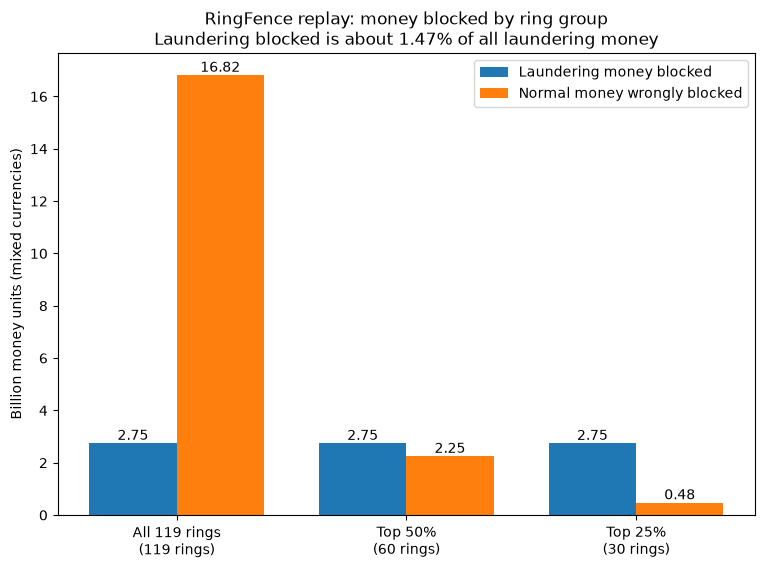

In [17]:
import matplotlib.pyplot as plt

groups = [("All 119 rings", 0), ("Top 50%", 0.5), ("Top 25%", 0.75)]
names, bad_list, good_list, pct_list = [], [], [], []

for label, q in groups:
    sel = ring_risk[ring_risk >= ring_risk.quantile(q)].index
    a_sel = after[after["ring"].isin(sel)]
    bad = a_sel.loc[a_sel["is_laundering"] == 1, "amt_paid"].sum()
    good = a_sel.loc[a_sel["is_laundering"] == 0, "amt_paid"].sum()
    names.append(label + "\n(" + str(len(sel)) + " rings)")
    bad_list.append(bad / 1e9)
    good_list.append(good / 1e9)
    pct_list.append(100 * bad / total_bad)

x = list(range(len(names)))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 6))
b1 = ax.bar([i - w / 2 for i in x], bad_list, w, label="Laundering money blocked")
b2 = ax.bar([i + w / 2 for i in x], good_list, w, label="Normal money wrongly blocked")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height(),
                str(round(r.get_height(), 2)), ha="center", va="bottom", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Billion money units (mixed currencies)")
ax.set_title("RingFence replay: money blocked by ring group\n"
             "Laundering blocked is about " + str(round(pct_list[0], 2)) + "% of all laundering money")
ax.legend()
plt.show()

In [1]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score

T = df["timestamp"].quantile(0.6)
early = df[df["timestamp"] <= T]
late = df[df["timestamp"] > T]
print("split time:", T)
print("early transactions:", len(early), "| late transactions:", len(late))

def build_feats(d):
    o = d.groupby("src").agg(out_count=("dst", "size"),
                             fan_out=("dst", "nunique"),
                             out_amt=("amt_paid", "sum"))
    i = d.groupby("dst").agg(in_count=("src", "size"),
                             fan_in=("src", "nunique"),
                             in_amt=("amt_paid", "sum"))
    f = o.join(i, how="outer").fillna(0)
    bad = pd.concat([d.loc[d["is_laundering"] == 1, "src"],
                     d.loc[d["is_laundering"] == 1, "dst"]]).unique()
    f["label"] = f.index.isin(bad).astype(int)
    return f

f_early = build_feats(early)
f_late = build_feats(late)
print("early accounts:", len(f_early), "| late accounts:", len(f_late))

model_t = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1,
                             scale_pos_weight=80, verbose=-1)
model_t.fit(f_early[cols], f_early["label"])

proba_t = model_t.predict_proba(f_late[cols])[:, 1]
print("AUC on later period:", round(roc_auc_score(f_late["label"], proba_t), 3))
for t in [0.5, 0.8]:
    p = (proba_t > t).astype(int)
    print("cutoff", t,
          "| flagged:", int(p.sum()),
          "| precision:", round(precision_score(f_late["label"], p, zero_division=0), 3),
          "| recall:", round(recall_score(f_late["label"], p), 3))

NameError: name 'df' is not defined

In [2]:
import pandas as pd
import glob
import lightgbm as lgb

files = glob.glob("*.csv.gz")
print(files)

df = pd.read_csv(files[0])
if df.shape[1] != 11:
    print("Unexpected number of columns:", df.shape[1])
    print(list(df.columns))
else:
    df.columns = ["timestamp", "from_bank", "from_acct", "to_bank", "to_acct",
                  "amt_received", "recv_currency", "amt_paid", "pay_currency",
                  "pay_format", "is_laundering"]
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["src"] = df["from_bank"].astype(str) + "_" + df["from_acct"].astype(str)
    df["dst"] = df["to_bank"].astype(str) + "_" + df["to_acct"].astype(str)
    cols = ["out_count", "fan_out", "out_amt", "in_count", "fan_in", "in_amt"]
    print("rows:", len(df))
    print("loaded and ready")

['HI-Small_Trans.csv.gz']
rows: 5078345
loaded and ready


In [3]:
import hashlib, hmac, secrets, random

accounts = list(pd.unique(pd.concat([df["src"], df["dst"]])))
print("accounts the attacker is assumed to know:", len(accounts))

random.seed(1)
victims = random.sample(accounts, 2000)

key = secrets.token_bytes(32)

def plain_token(a):
    return hashlib.sha256(a.encode()).hexdigest()[:16]

def keyed_token(a):
    return hmac.new(key, a.encode(), hashlib.sha256).hexdigest()[:16]

shared_plain = set(plain_token(a) for a in victims)
shared_keyed = set(keyed_token(a) for a in victims)

lookup = {plain_token(a): a for a in accounts}

cracked_plain = sum(1 for t in shared_plain if t in lookup)
cracked_keyed = sum(1 for t in shared_keyed if t in lookup)

print("tokens shared:", len(victims))
print("plain hash tokens cracked:", cracked_plain, "of", len(victims))
print("keyed hash tokens cracked:", cracked_keyed, "of", len(victims))

accounts the attacker is assumed to know: 515088
tokens shared: 2000
plain hash tokens cracked: 2000 of 2000
keyed hash tokens cracked: 0 of 2000
